# 06 — Modelos: línea base, LightGBM, calibración, métricas y SHAP

**Etapa A (clasificación):** ¿se recupera algo? → regresión logística (línea base) vs LightGBM.
**Etapa B (regresión):** ¿qué % de la exposición se recupera, si se recupera? → promedio (línea base) vs LightGBM.
**Combinado:** monto esperado = P(A) × tasa esperada × saldo estimado al default.

**Regla de oro:** la validación (cierres 2010+) **no se usa para ajustar nada**. La parada temprana y la calibración usan el 25 % más reciente del entrenamiento (bloque de control).

**Resultados que guarda:** `models/modelo_A.joblib`, `models/modelo_B.joblib`, `models/metricas.json`, `docs/metricas_*.csv` y gráficas `docs/figuras/06_*.png`.

## 1. Preparación

In [1]:
import sys, json, warnings
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from src.config import RUTAS
from src.bd import obtener_motor
from src.variables import leer_base, construir_variables, saldo_al_default
from src.modelos import ModeloClasificacion, ModeloTasa, particion_interna
from src.metricas import (metricas_clasificacion, metricas_regresion, tabla_deciles,
                          curva_ganancia, captura_en)

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', message='.*eval_set.*')  # aviso de versión de LightGBM, no afecta
pd.set_option('display.width', 160)

def guardar_figura(fig, nombre):
    fig.savefig(RUTAS['figuras'] / nombre, dpi=150, bbox_inches='tight')

## 2. Datos desde PostgreSQL y contrato de variables

In [2]:
base = leer_base(obtener_motor())
X_todas = construir_variables(base)
contrato = json.loads((RUTAS['models'] / 'variables.json').read_text(encoding='utf-8'))
NUM, CAT = contrato['numericas'], contrato['categoricas']

# Saldo contractual estimado al default (en USD): exposición conocida al entrar a cobranza
saldo = saldo_al_default(base)
ratio_mediano = (saldo / base['monto_original']).median()
base['saldo_estimado'] = saldo.fillna(base['monto_original'] * ratio_mediano)

ent = base['conjunto'].eq('entrenamiento').to_numpy()
val = base['conjunto'].eq('validacion').to_numpy()
ajuste, control = particion_interna(base.loc[ent, 'fecha_cierre'])

X_ent, X_val = X_todas[ent], X_todas[val]
yA_ent, yA_val = base.loc[ent, 'objetivo_a'].to_numpy(), base.loc[val, 'objetivo_a'].to_numpy()
usd_val = base.loc[val, 'recuperacion_total'].to_numpy()

print(f'Variables del contrato: {len(NUM)} numéricas + {len(CAT)} categóricas')
print(f'Entrenamiento: {ent.sum():,}  (ajuste {ajuste.sum():,} | control {control.sum():,})')
print(f'Validación:    {val.sum():,}')

Variables del contrato: 33 numéricas + 0 categóricas
Entrenamiento: 8,543  (ajuste 6,413 | control 2,130)
Validación:    3,163


## 3. Etapa A — Línea base vs LightGBM
📋 **Pega esta tabla.**

In [3]:
modelos_A = {
    'Logística (base)': ModeloClasificacion('logistica', NUM, CAT),
    'LightGBM': ModeloClasificacion('lightgbm', NUM, CAT),
}
for nombre, m in modelos_A.items():
    m.fit(X_ent[ajuste], yA_ent[ajuste], X_ent[control], yA_ent[control])

pred_A = {n: m.predict_proba(X_val) for n, m in modelos_A.items()}
tabla_A = pd.DataFrame([metricas_clasificacion(yA_val, p, n) for n, p in pred_A.items()])
tabla_A['captura_usd_top20'] = [round(captura_en(p, usd_val, 0.2), 4) for p in pred_A.values()]
print('Árboles de LightGBM (parada temprana):', modelos_A['LightGBM'].n_arboles_)
tabla_A

Árboles de LightGBM (parada temprana): 179


,modelo,auc_roc,pr_auc,pr_auc_azar,brier,brier_tasa_base,prob_media,tasa_real,captura_usd_top20
0,Logística (base),0.6365,0.5397,0.2969,0.1850,0.2087,0.2866,0.2969,0.4317
1,LightGBM,0.6438,0.5159,0.2969,0.1859,0.2087,0.2562,0.2969,0.3998


## 4. Experimento: ¿vale la pena recuperar las variables del bureau?
Las 11 variables del bureau se excluyeron en la Fase 5 porque faltan en el 35 % del entrenamiento (créditos antiguos). Aquí probamos un modelo **con** ellas, entrenado solo con los créditos que sí las tienen, y lo comparamos con el modelo base **en el mismo grupo de validación**.

📋 **Pega esta tabla.**

In [4]:
BUREAU = [c for c, razon in contrato['excluidas'].items()
          if razon.startswith('Diferencia de nulos') and c in X_todas.columns]
tiene_bureau = X_todas['obligaciones_totales'].notna().to_numpy()
print(f'Variables del bureau: {len(BUREAU)}')

m_bur = ModeloClasificacion('lightgbm', NUM + BUREAU, CAT)
aj_b, ct_b = ajuste & tiene_bureau[ent], control & tiene_bureau[ent]
m_bur.fit(X_ent[aj_b], yA_ent[aj_b], X_ent[ct_b], yA_ent[ct_b])

sub = tiene_bureau[val]
filas = []
for nombre, m in [('LightGBM (35 variables)', modelos_A['LightGBM']), ('LightGBM + bureau', m_bur)]:
    p_sub, p_tot = m.predict_proba(X_val[sub]), m.predict_proba(X_val)
    filas.append({'modelo': nombre,
                  'creditos_entrenamiento': int((aj_b | ct_b).sum()) if 'bureau' in nombre else int(ent.sum()),
                  'auc_validacion_con_bureau': round(metricas_clasificacion(yA_val[sub], p_sub, nombre)['auc_roc'], 4),
                  'auc_validacion_total': round(metricas_clasificacion(yA_val, p_tot, nombre)['auc_roc'], 4),
                  'captura_usd_top20_total': round(captura_en(p_tot, usd_val, 0.2), 4)})
experimento = pd.DataFrame(filas)
print(f'Validación con bureau: {sub.sum():,} de {val.sum():,} créditos')
experimento

Variables del bureau: 11
Validación con bureau: 3,089 de 3,163 créditos


,modelo,creditos_entrenamiento,auc_validacion_con_bureau,auc_validacion_total,captura_usd_top20_total
0,LightGBM (35 variables),8543,0.6441,0.6438,0.3998
1,LightGBM + bureau,5551,0.6346,0.6333,0.3422


## 4b. Sensibilidad: ¿cuánto costó sacar `estado_residencia` y `ocupacion`?
En la primera ejecución, SHAP mostró que el modelo usaba la categoría **"Sin dato"** de `estado_residencia` (más frecuente en créditos antiguos) como señal. Por la regla fijada en D25, ambas variables salen del modelo **por principio**, no por su AUC. Aquí solo medimos el costo de esa decisión.

📋 **Pega esta tabla.**

In [5]:
VIGILADAS = [c for c in ['estado_residencia', 'ocupacion'] if c in contrato['excluidas']]
m_vig = ModeloClasificacion('lightgbm', NUM, CAT + VIGILADAS)
m_vig.fit(X_ent[ajuste], yA_ent[ajuste], X_ent[control], yA_ent[control])
p_vig = m_vig.predict_proba(X_val)
sensibilidad = pd.DataFrame([
    {'modelo': 'LightGBM sin variables de época (oficial)', 'auc_roc': tabla_A.loc[1, 'auc_roc'],
     'captura_usd_top20': tabla_A.loc[1, 'captura_usd_top20']},
    {'modelo': f'LightGBM + {", ".join(VIGILADAS)}', 'auc_roc': round(metricas_clasificacion(yA_val, p_vig, '')['auc_roc'], 4),
     'captura_usd_top20': round(captura_en(p_vig, usd_val, 0.2), 4)},
])
sensibilidad

,modelo,auc_roc,captura_usd_top20
0,LightGBM sin variables de época (oficial),0.6438,0.3998
1,"LightGBM + estado_residencia, ocupacion",0.6571,0.3868


## 5. Elección del modelo A
Regla fijada **antes** de ver los resultados: se elige el candidato con mayor **AUC en toda la validación**; si dos quedan a menos de 0,005, se prefiere el más simple (menos variables o la logística).

In [6]:
candidatos = {
    'Logística (base)': (modelos_A['Logística (base)'], tabla_A.loc[0, 'auc_roc'], 0),
    'LightGBM': (modelos_A['LightGBM'], tabla_A.loc[1, 'auc_roc'], 1),
    'LightGBM + bureau': (m_bur, experimento.loc[1, 'auc_validacion_total'], 2),
}
mejor_auc = max(v[1] for v in candidatos.values())
NOMBRE_A = min((n for n, v in candidatos.items() if v[1] >= mejor_auc - 0.005),
               key=lambda n: candidatos[n][2])
modelo_A = candidatos[NOMBRE_A][0]
p_val = modelo_A.predict_proba(X_val)
print(f'✅ Modelo A elegido: {NOMBRE_A}  (AUC validación = {candidatos[NOMBRE_A][1]:.4f})')

✅ Modelo A elegido: LightGBM  (AUC validación = 0.6438)


## 6. Lift por decil y curva de ganancia (modelo A elegido)
Esto es lo que importa para cobranza: **si contacto primero a los de mayor puntaje, ¿cuánto capturo?**

📋 **Pega la tabla de deciles.**

,creditos,puntaje_medio,tasa_recupera,usd_recuperado,lift,pct_recuperadores_acum,pct_usd_acum
decil,,,,,,,
1,317,0.6304,0.6656,353139.58,2.2421,0.2247,0.2987
2,316,0.3007,0.3386,119496.47,1.1406,0.3387,0.3998
3,316,0.2622,0.2848,116767.03,0.9594,0.4345,0.4986
4,317,0.2401,0.3155,101619.74,1.0626,0.5410,0.5845
5,316,0.2239,0.2278,65874.70,0.7675,0.6177,0.6402
6,316,0.2104,0.2753,94476.92,0.9274,0.7103,0.7202
7,317,0.1983,0.2303,78522.25,0.7757,0.7881,0.7866
8,316,0.1852,0.2753,98059.56,0.9274,0.8807,0.8695
9,316,0.1697,0.1962,90138.75,0.6609,0.9468,0.9458


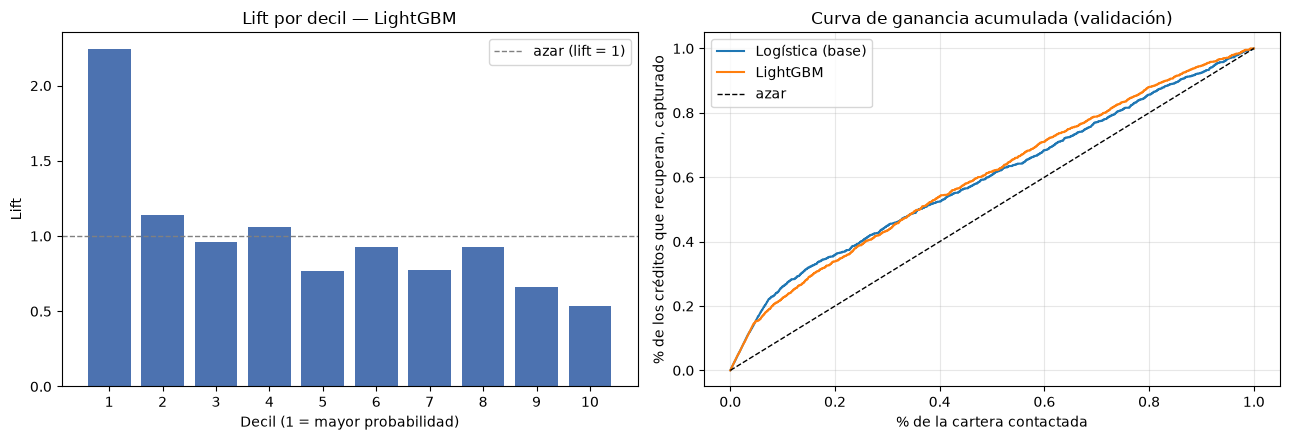

In [7]:
deciles = tabla_deciles(p_val, yA_val, usd_val)
display(deciles)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(deciles.index, deciles['lift'], color='#4C72B0')
axes[0].axhline(1, color='gray', ls='--', lw=1, label='azar (lift = 1)')
axes[0].set_xticks(deciles.index); axes[0].set_xlabel('Decil (1 = mayor probabilidad)')
axes[0].set_ylabel('Lift'); axes[0].set_title(f'Lift por decil — {NOMBRE_A}'); axes[0].legend()

for nombre, p in pred_A.items():
    x, y = curva_ganancia(p, yA_val)
    axes[1].plot(x, y, label=nombre)
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='azar')
axes[1].set_xlabel('% de la cartera contactada'); axes[1].set_ylabel('% de los créditos que recuperan, capturado')
axes[1].set_title('Curva de ganancia acumulada (validación)'); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); guardar_figura(fig, '06_lift_ganancia_A.png'); plt.show()

## 7. Calibración
¿Una probabilidad de 30 % significa que recupera ~30 % de las veces? La validación tiene una tasa base mayor que el entrenamiento (29,7 % vs 23,5 %), así que se espera que el modelo **subestime** un poco: lo medimos y lo reportamos.

📋 **Pega la línea de Brier y la tabla.**

Brier sin calibrar: 0.1888 | calibrado: 0.1859 | solo tasa base: 0.2087


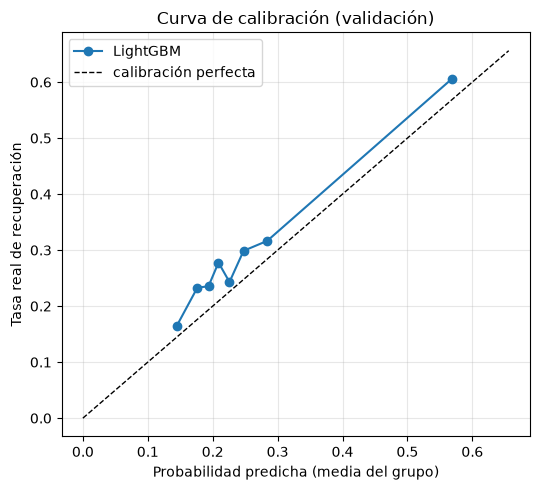

,prob_predicha,tasa_real
0,0.144,0.164
1,0.176,0.233
2,0.194,0.235
3,0.209,0.278
4,0.226,0.243
5,0.248,0.299
6,0.284,0.316
7,0.569,0.606


In [8]:
from sklearn.calibration import calibration_curve

frac_pos, prob_media = calibration_curve(yA_val, p_val, n_bins=8, strategy='quantile')
p_sin_cal = modelo_A.predict_proba(X_val, calibrada=False)
from sklearn.metrics import brier_score_loss
print(f'Brier sin calibrar: {brier_score_loss(yA_val, p_sin_cal):.4f} | calibrado: {brier_score_loss(yA_val, p_val):.4f} '
      f'| solo tasa base: {brier_score_loss(yA_val, np.full(len(yA_val), yA_val.mean())):.4f}')

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(prob_media, frac_pos, marker='o', label=NOMBRE_A)
lim = max(prob_media.max(), frac_pos.max()) + 0.05
ax.plot([0, lim], [0, lim], 'k--', lw=1, label='calibración perfecta')
ax.set_xlabel('Probabilidad predicha (media del grupo)'); ax.set_ylabel('Tasa real de recuperación')
ax.set_title('Curva de calibración (validación)'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); guardar_figura(fig, '06_calibracion.png'); plt.show()
pd.DataFrame({'prob_predicha': prob_media.round(3), 'tasa_real': frac_pos.round(3)})

## 8. Robustez: sin los deudores que también están en entrenamiento

In [9]:
limpio = ~base.loc[val, 'deudor_visto_en_entrenamiento'].to_numpy() if 'deudor_visto_en_entrenamiento' in base else None
if limpio is None:
    ids_ent = set(base.loc[ent, 'member_key'])
    limpio = ~base.loc[val, 'member_key'].isin(ids_ent).to_numpy()
print(f'AUC validación completa: {metricas_clasificacion(yA_val, p_val, "")["auc_roc"]:.4f}')
print(f'AUC sin deudores repetidos ({(~limpio).sum()} excluidos): '
      f'{metricas_clasificacion(yA_val[limpio], p_val[limpio], "")["auc_roc"]:.4f}')

AUC validación completa: 0.6438
AUC sin deudores repetidos (15 excluidos): 0.6439


## 9. Etapa B — Tasa de recuperación (solo créditos que recuperan algo)
📋 **Pega esta tabla.**

In [10]:
rec_ent = ent & (base['objetivo_a'] == 1).to_numpy()
rec_val = val & (base['objetivo_a'] == 1).to_numpy()
aj_B, ct_B = particion_interna(base.loc[rec_ent, 'fecha_cierre'])
XB, yB = X_todas[rec_ent], base.loc[rec_ent, 'objetivo_b_tasa'].to_numpy()
yB_val = base.loc[rec_val, 'objetivo_b_tasa'].to_numpy()

modelos_B = {'Promedio (base)': ModeloTasa('media', NUM, CAT), 'LightGBM': ModeloTasa('lightgbm', NUM, CAT)}
for m in modelos_B.values():
    m.fit(XB[aj_B], yB[aj_B], XB[ct_B], yB[ct_B])

tabla_B = pd.DataFrame([metricas_regresion(yB_val, m.predict(X_todas[rec_val]), n) for n, m in modelos_B.items()])
NOMBRE_B = 'LightGBM' if tabla_B.loc[1, 'mae'] < tabla_B.loc[0, 'mae'] else 'Promedio (base)'
modelo_B = modelos_B[NOMBRE_B]
print(f'Créditos con A=1 → entrenamiento: {rec_ent.sum():,} | validación: {rec_val.sum():,}')
print(f'Tasa media real → entrenamiento: {yB.mean():.3f} | validación: {yB_val.mean():.3f}')
print(f'✅ Modelo B elegido (menor MAE): {NOMBRE_B}')
tabla_B

Créditos con A=1 → entrenamiento: 2,009 | validación: 939
Tasa media real → entrenamiento: 0.322 | validación: 0.527
✅ Modelo B elegido (menor MAE): LightGBM


,modelo,mae,rmse,r2
0,Promedio (base),0.3980,0.4678,-0.3527
1,LightGBM,0.3406,0.4030,-0.0037


## 10. Combinado: monto esperado y ganancia en dólares
**Monto esperado = P(recuperar) × tasa esperada × saldo estimado al default.** Comparamos tres formas de ordenar la cartera de validación: al azar, por probabilidad (solo etapa A), por probabilidad × saldo (para aislar el aporte de la etapa B) y por monto esperado (A × B × saldo).

📋 **Pega esta tabla.**

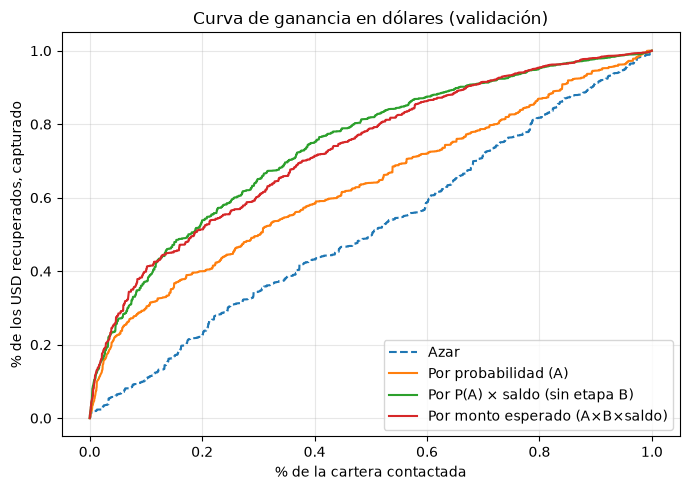

USD recuperados en validación: 1,182,216 | suma de montos esperados: 908,338


,orden,captura_usd_top10,captura_usd_top20,captura_usd_top30,captura_usd_top50
0,Azar,0.1059,0.2264,0.3446,0.4973
1,Por probabilidad (A),0.2987,0.3998,0.4986,0.6402
2,Por P(A) × saldo (sin etapa B),0.3720,0.5384,0.6508,0.8189
3,Por monto esperado (A×B×saldo),0.3988,0.5135,0.6027,0.7884


In [11]:
tasa_val = modelo_B.predict(X_val)
monto_esp = p_val * tasa_val * base.loc[val, 'saldo_estimado'].to_numpy()

rng = np.random.default_rng(42)
saldo_val = base.loc[val, 'saldo_estimado'].to_numpy()
ordenes = {'Azar': rng.random(val.sum()),
           'Por probabilidad (A)': p_val,
           'Por P(A) × saldo (sin etapa B)': p_val * saldo_val,
           'Por monto esperado (A×B×saldo)': monto_esp}
filas = [{'orden': n, **{f'captura_usd_top{int(f*100)}': round(captura_en(s, usd_val, f), 4)
                       for f in (0.1, 0.2, 0.3, 0.5)}} for n, s in ordenes.items()]
ganancia_usd = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(7, 5))
for n, s in ordenes.items():
    x, y = curva_ganancia(s, usd_val)
    ax.plot(x, y, label=n, ls='--' if n == 'Azar' else '-')
ax.set_xlabel('% de la cartera contactada'); ax.set_ylabel('% de los USD recuperados, capturado')
ax.set_title('Curva de ganancia en dólares (validación)'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); guardar_figura(fig, '06_ganancia_usd.png'); plt.show()

print(f'USD recuperados en validación: {usd_val.sum():,.0f} | suma de montos esperados: {monto_esp.sum():,.0f}')
ganancia_usd

## 11. Explicabilidad con SHAP
¿Qué variables mueven la probabilidad de recuperar? También revisamos si la categoría **"Sin dato"** (que depende de la época) pesa en el modelo.

📋 **Pega la tabla de importancia y el control de "Sin dato".**

c:\Users\Cindy\Proyecto ll\cobranza-ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


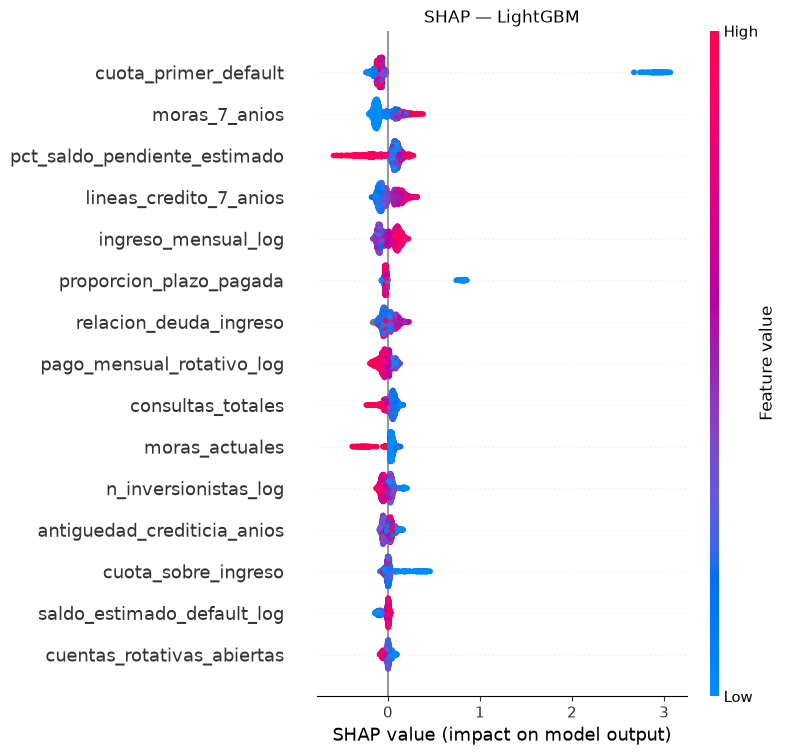

Control de "Sin dato" (SHAP medio de esa categoría vs. el resto):


,variable,shap_medio_abs
0,cuota_primer_default,0.220688
1,moras_7_anios,0.115770
2,pct_saldo_pendiente_estimado,0.110404
3,lineas_credito_7_anios,0.090496
4,ingreso_mensual_log,0.082655
5,proporcion_plazo_pagada,0.061182
6,relacion_deuda_ingreso,0.055423
7,pago_mensual_rotativo_log,0.053798
8,consultas_totales,0.051900
9,moras_actuales,0.050479


In [12]:
import shap

muestra = X_val.sample(min(2000, len(X_val)), random_state=42)
if modelo_A.tipo == 'lightgbm':
    Xm = modelo_A._preparar(muestra)
    valores = shap.TreeExplainer(modelo_A.estimador_).shap_values(Xm)
    valores = valores[1] if isinstance(valores, list) else valores
    X_graf = Xm.copy()
    for c in modelo_A.categoricas:
        X_graf[c] = X_graf[c].cat.codes
    importancia = (pd.DataFrame({'variable': Xm.columns, 'shap_medio_abs': np.abs(valores).mean(0)})
                   .sort_values('shap_medio_abs', ascending=False).reset_index(drop=True))
    shap.summary_plot(valores, X_graf, max_display=15, show=False)
    plt.title(f'SHAP — {NOMBRE_A}'); guardar_figura(plt.gcf(), '06_shap_resumen.png'); plt.show()

    print('Control de "Sin dato" (SHAP medio de esa categoría vs. el resto):')
    for c in modelo_A.categoricas:
        es_sd = (muestra[c].astype(str) == 'Sin dato').to_numpy()
        j = list(Xm.columns).index(c)
        if es_sd.any():
            print(f'  {c}: "Sin dato" = {valores[es_sd, j].mean():+.4f} ({es_sd.mean():.1%} de la muestra) | '
                  f'resto = {valores[~es_sd, j].mean():+.4f}')
else:
    est = modelo_A.estimador_
    nombres = est.named_steps['prep'].get_feature_names_out()
    importancia = (pd.DataFrame({'variable': nombres, 'coeficiente': est.named_steps['modelo'].coef_[0]})
                   .assign(abs=lambda d: d['coeficiente'].abs()).sort_values('abs', ascending=False)
                   .drop(columns='abs').reset_index(drop=True))
importancia.head(15)

## 12. Guardar modelos y métricas

In [13]:
joblib.dump(modelo_A, RUTAS['models'] / 'modelo_A.joblib')
joblib.dump(modelo_B, RUTAS['models'] / 'modelo_B.joblib')

metricas = {
    'modelo_A': NOMBRE_A, 'modelo_B': NOMBRE_B,
    'validacion_A': metricas_clasificacion(yA_val, p_val, NOMBRE_A),
    'validacion_B': metricas_regresion(yB_val, modelo_B.predict(X_todas[rec_val]), NOMBRE_B),
    'captura_usd': ganancia_usd.set_index('orden').to_dict(orient='index'),
    'lift_decil_1': float(deciles.loc[1, 'lift']),
    'ratio_saldo_mediano': float(ratio_mediano),
}
(RUTAS['models'] / 'metricas.json').write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding='utf-8')
tabla_A.to_csv(RUTAS['docs'] / 'metricas_A.csv', index=False, encoding='utf-8-sig')
sensibilidad.to_csv(RUTAS['docs'] / 'metricas_sensibilidad_vigiladas.csv', index=False, encoding='utf-8-sig')
experimento.to_csv(RUTAS['docs'] / 'metricas_experimento_bureau.csv', index=False, encoding='utf-8-sig')
deciles.to_csv(RUTAS['docs'] / 'metricas_deciles.csv', encoding='utf-8-sig')
tabla_B.to_csv(RUTAS['docs'] / 'metricas_B.csv', index=False, encoding='utf-8-sig')
ganancia_usd.to_csv(RUTAS['docs'] / 'metricas_ganancia_usd.csv', index=False, encoding='utf-8-sig')
importancia.to_csv(RUTAS['docs'] / 'metricas_importancia.csv', index=False, encoding='utf-8-sig')

for f in ['modelo_A.joblib', 'modelo_B.joblib']:
    print(f'✅ models/{f}  ({(RUTAS["models"] / f).stat().st_size / 1024:.0f} KB)')
print('✅ models/metricas.json, docs/metricas_*.csv, docs/figuras/06_*.png')

✅ models/modelo_A.joblib  (328 KB)
✅ models/modelo_B.joblib  (701 KB)
✅ models/metricas.json, docs/metricas_*.csv, docs/figuras/06_*.png
